# Cutting long permits and filings into pieces a search can find

## A question about a permit

A cement plant in Atlanta runs under an air permit issued by Georgia's environmental agency. A permit is the regulator's written list of what a facility may release into the air or water, and of what it must check, record and report to show that it stays within those limits. This one is 44 pages of numbered conditions. Suppose someone at the plant, or an inspector, wants to know how often the baghouses, the fabric filters that catch dust, must be checked for visible emissions. The answer is in condition 5.2.1 on page 12: at least once for each day the plant operates.

Finding that by hand takes a few minutes for one permit. A company with many sites may hold dozens of permits, each reissued every few years, along with settlements, rate filings and inspection reports, some of them hundreds of pages long. So teams put such documents behind a search tool. The tool returns the passages most closely related to a question, and either a person reads them or a language model writes an answer from them. The second arrangement is called retrieval-augmented generation, or RAG.

The search does not look at whole documents. Each document is first cut into pieces of a few hundred words, called chunks. A model turns each chunk into an embedding: a list of numbers chosen so that texts with similar meaning get similar numbers. The question gets an embedding too, and the search returns the chunks whose numbers are closest to it. A chunk is the smallest thing the search can return, so where the cuts fall decides what the reader gets back.

### An illustrative example

This example is simplified from the Georgia permit tested below.

Part 5 of the permit covers monitoring. Section 5.1 sets general rules for monitoring equipment. Section 5.2 starts the specific requirements, and its first condition, 5.2.1, is the daily baghouse check, followed by its steps a to d. Suppose every chunk may hold at most 400 tokens. A token is a word or a piece of a word, so 400 tokens is a few hundred words.

In the ordinary case the cut goes just before the heading "5.2 Specific Monitoring Requirements". The chunk then opens with the heading and holds the whole baghouse condition. A search about baghouse checks finds it, and the reader sees the section number to cite.

Now add one complication. A cutter that only counts tokens puts a cut every 400 tokens, wherever the count runs out. One chunk might hold the end of the testing rules in section 4.2 and the first lines of 5.2.1, and the next chunk the rest of the condition. The search may return the half without the answer, and a chunk that mixes two topics resembles neither of them closely.

A second complication runs the other way. Cutting at every section start is not always safe, because a question can need a passage that crosses a heading: the last row of a table and the heading under it, or the case number on a cover page and the document title below it. A cut at a correct section start then splits the passage the question needs. A person reading the permit simply keeps reading; a search returns one chunk at a time.

### Two ways to cut

One way ignores the content. It cuts every 400 tokens, or it splits at blank lines and sentence ends and packs the pieces back together up to 400 tokens. This is fast and free, and needs no model.

The other way reads the text to decide where sections start, then cuts there while keeping every chunk within 400 tokens. This study compares three readers. A heading rule spots lines typed like headings: numbered, in capitals, short. An embedding measure checks how much the topic changes between neighbouring paragraphs. A decision model is asked about each paragraph whether a new section starts there. A decision model answers a question that has a fixed set of answers by returning a probability for each answer, instead of writing text. The one tested here is OpenAI's Decisions API. All three readers give each paragraph a probability that a section starts there, and one shared procedure turns those probabilities into cuts, so the readers can be compared on equal terms. Below, the five cutters are called Fixed tokens, Recursive, Headings + DP, Semantic + DP (topic change) and Decisions + DP, where DP, short for dynamic programming, is that shared procedure.

The decision model costs money for every page it reads; the other methods cost nothing. A team building search over its permits needs three answers before paying: whether the model's cuts follow the documents' sections better, whether that helps the search find answers, and how often its cuts split an answer in two.

## The question

On 12 long public filings (water and air permits, a hazardous-waste permit, a settlement, two utility rate filings, a vehicle recall notice, a nursing-home inspection and a pesticide label), do chunks cut where the Decisions API says a section starts follow the documents' sections more closely than chunks cut by length, by a heading rule or by topic change? Does that help a search find the passages behind 276 question-and-quote pairs, and how often does a cut split a passage a question needs?

## Study summary

Five ways of cutting were compared under the same 400-token limit on 12 PDFs (1,306 pages, 694,127 tokens). Four of the PDFs carry bookmarks that mark 506 section starts, and these four test whether each method finds section starts and keeps sections apart. A bank of 142 questions with 276 evidence quotes tests whether a search over the chunks finds each quote among its top five results, and the 129 pairs whose quote is 600 characters or shorter test how often a quote is cut in two.

- Finding section starts: the Decisions API ranked real section starts above other paragraphs best, with an average precision of 0.35 against 0.21 for the heading rule and 0.20 for topic change; a random ranking would score about 0.10. It led on three of the four documents. The heading rule led on the 313-page Massachusetts permit (0.19 against 0.16), whose bookmarks mark each reply to a public comment as a section.
- Following sections: Decisions + DP put a cut within 200 characters of 77% of bookmarked section starts, and 6% of its chunks held two sections. Headings + DP reached 68% and 10%; Fixed tokens 26% and 28%.
- Finding the evidence: the search found the quoted passage in its top five chunks for 50% to 55% of the 276 pairs under every method, and the 95% intervals overlap. Cleaner sections did not make the search find more.
- Splitting answers: Decisions + DP kept 101 of the 129 short quotes whole (78%), against 118 to 120 (91% to 93%) for the other methods. Most of that gap is one quote. The 129 pairs repeat 47 distinct quotes, and 18 of the 28 splits are a single Con Edison cover page cited by 18 questions. Counting each distinct quote once, Decisions + DP kept 41 of 47 whole and the other methods 42 to 45.
- All 278 Decisions API calls returned a readable probability for each of the 8,713 paragraphs asked about, so no result depends on failed replies.

For the plant's question, this means a search built on the Decisions API's cuts returns chunks that line up with the permit's own numbered sections, for \$0.39 per million tokens of document, but it does not find the baghouse condition more often than a free cutter that counts tokens, and now and then it separates a table row or a cover-page title from the text around it.

The main caveat is that the section results rest on four documents whose bookmarks mark only some of their sections, and the question bank repeats quotes and words many questions as long templated instructions, so the search results describe this question bank more than search in general. This notebook also predates the repository's rule that test documents must be newer than the models: the documents are public filings that the catalogue dates between 2021 and 2026, no training cutoff is recorded for either model, and the scores should be read as an upper bound.

## Contents

1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Chunkers](#3.-Chunkers)
4. [Build all chunkings](#4.-Build-all-chunkings)
5. [Results](#5.-Results)
6. [Error analysis](#6.-Error-analysis)
7. [What the evidence supports](#7.-What-the-evidence-supports)
8. [Limitations](#8.-Limitations)
9. [How to reproduce](#9.-How-to-reproduce)
10. [Future work and further reading](#10.-Future-work-and-further-reading)

## Workflow

The whole experiment from the PDFs to the three tests, with the counts from this run. Every model response is cached in `data/`, so a re-run replays it without model calls.

```mermaid
flowchart TD
    docs["12 public PDFs, sha256-pinned<br/>1,306 pages, 694,127 tokens"] --> ext["Extract text blocks (PyMuPDF)<br/>20,800 blocks; 522 bookmarked starts located"]
    qs["Question banks in data/catalog<br/>284 question-quote pairs, 144 questions"] --> loc["Locate each quote in the text<br/>276 found (142 questions, 116 distinct quotes); 8 not found"]
    ext --> loc
    ext --> units["Candidate paragraphs<br/>blocks merged to at least 40 tokens, split above 200<br/>8,725 paragraphs"]
    ext --> base["Fixed tokens, Recursive<br/>no model"]
    units --> head["Heading rule<br/>no model"]
    units --> sem["Topic change<br/>free embedding model"]
    units --> dec["Decisions API (OpenRouter)<br/>278 calls, 8,713 probabilities, $0.27"]
    head --> dp["Shared cut-placing step (DP)<br/>chunks of at most 400 tokens"]
    sem --> dp
    dec --> dp
    base --> chunks["5 chunkings<br/>1,987 to 2,659 chunks each"]
    dp --> chunks
    head --> ev1["Finding section starts<br/>4 bookmarked PDFs, 5,815 paragraphs, 376 starts"]
    sem --> ev1
    dec --> ev1
    chunks --> ev2["Chunks and sections<br/>4 bookmarked PDFs, 506 starts"]
    chunks --> ev3["Search over one index of all 12 PDFs<br/>276 pairs; 129 short quotes checked for splits"]
    loc --> ev3
```

One question-quote pair travels through it as follows: the quote is located in the extracted text, the three readers score the document's candidate paragraphs, each cutter makes its chunks, the chunks of all twelve PDFs form one search index per cutter, and the question is searched to see where the first chunk holding the quote ranks. Section 5.4 follows one pair from the Georgia permit through every step.

## 1. Setup

The next cell imports the libraries, sets the folder paths and fixes the settings every chunker shares: chunks of at most 400 tokens, a penalty for chunks under 100 tokens, and candidate paragraphs of 40 to 200 tokens. It also names the two models. Token counts everywhere use the `o200k_base` tokenizer from the `tiktoken` library.

The notebook runs offline. Every model response is cached in `data/`, so a re-run replays from disk and needs no key; `OPENROUTER_API_KEY` is needed only for a request that is not cached. Dependencies are in `requirements.txt` at the repository root.

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| OpenAI Decisions API | `openai/gpt-6-luna-decisions` as requested; the cached replies carry no model or version field, so no dated version was recorded | OpenAI, through OpenRouter's Decisions endpoint (`/api/alpha/decisions`), one HTTP call per window | Not published | 32 yes/no (`noul`) questions per call, each returning a probability; no sampling settings | The method under test: a decision model that gives the probability that a paragraph starts a new section |
| Llama Nemotron Embed VL 1B v2 | `nvidia/llama-nemotron-embed-vl-1b-v2:free` as requested; no dated version recorded | NVIDIA open-weight model, OpenRouter free endpoint | About 1B parameters (from the name); precision not recorded | 512-number vectors, normalised | Scores topic change for Semantic + DP and builds the search index for all five cutters at no cost |

`data/` records no release date or training cutoff for either model. The embedding endpoint is free (1,000 requests a day per key) and may log its inputs, which is acceptable for public filings and would not be for private documents. The Decisions endpoint has no free variant; its spend is printed in section 5.5.

In [1]:
import csv, hashlib, json, os, re, shutil, threading, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import requests
import tiktoken
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd()  # this notebook's folder
DATA = ROOT / "data"
CAT, DOCS = DATA / "catalog", DATA / "docs"
DOCS.mkdir(parents=True, exist_ok=True)

DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
DECISIONS_MODEL = "openai/gpt-6-luna-decisions"
EMBED_MODEL = "nvidia/llama-nemotron-embed-vl-1b-v2:free"  # free
MAX_CHUNK, MIN_CHUNK = 400, 100   # token budget shared by every chunker
MIN_UNIT, MAX_UNIT = 40, 200      # candidate "paragraph" units for the boundary scorers
WORKERS = 8

HEADERS = {"Authorization": f"Bearer {os.environ.get('OPENROUTER_API_KEY', '')}"}  # only used on a cache miss
enc = tiktoken.get_encoding("o200k_base")
ntok = lambda s: len(enc.encode(s, disallowed_special=()))
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 1.1 Helpers

These helpers make every model call repeatable and free to replay. `post()` sends a request and retries when the service is busy or briefly failing (HTTP 429 and 5xx), waiting longer each time; it raises `Refused` when the Decisions service declines to answer, since a retry would not help. `JsonlCache` stores each Decisions reply in `data/decisions_cache_chunking.jsonl` under a hash of the full request (model, evidence text and questions), so the same request is never sent twice. `decide()` makes one Decisions call through that cache. `embed()` returns normalised 512-number embeddings, cached per text in `data/embeddings_cache.npz`. Nothing is printed.

In [2]:
class Refused(Exception):
    """The model declined to answer (HTTP 502 'refused to answer'); not worth retrying."""


def post(url, payload, tries=8):
    """POST with exponential backoff on 429/5xx; raises on any other error."""
    if not os.environ.get("OPENROUTER_API_KEY"):
        raise RuntimeError(f"Not in the cache and OPENROUTER_API_KEY is not set ({url})")
    for attempt in range(tries):
        r = requests.post(url, json=payload, headers=HEADERS, timeout=180)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 502 and "refused" in r.text:
            raise Refused(r.text[:200])
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(min(60, 5 * 2**attempt) if r.status_code == 429 else 2**attempt)  # free models rate-limit harder
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:400]}")


class JsonlCache:
    """Append-only on-disk cache for API responses, keyed by the request payload."""

    def __init__(self, path):
        self.path, self.lock, self.data = path, threading.Lock(), {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, payload, fn):
        key = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
        if key not in self.data:
            value = fn(payload)
            with self.lock:
                self.data[key] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": key, "value": value}) + "\n")
        return self.data[key]


decision_cache = JsonlCache(DATA / "decisions_cache_chunking.jsonl")


def decide(state, questions):
    """One Decisions API call. Returns {'answers', 'usage', 'latency_s'}; raises Refused."""

    def call(payload):
        t0 = time.perf_counter()
        try:
            out = post(DECISIONS_URL, payload)
        except Refused as e:
            return {"refused": str(e)}
        return {"answers": out["answers"], "usage": out["usage"], "latency_s": time.perf_counter() - t0}

    result = decision_cache.get({"model": DECISIONS_MODEL, "state": state, "questions": questions}, call)
    if "refused" in result:
        raise Refused(result["refused"])
    return result


EMB_PATH = DATA / "embeddings_cache.npz"
if EMB_PATH.exists():
    with np.load(EMB_PATH) as z:  # plain arrays, no pickle
        emb_cache = dict(zip(z["keys"].tolist(), z["vectors"]))
else:
    emb_cache = {}


def save_emb_cache():
    keys = list(emb_cache)
    np.savez(EMB_PATH, keys=np.array(keys), vectors=np.stack([emb_cache[k] for k in keys]).astype(np.float32))


def embed(texts, batch=256):
    """L2-normalised embeddings (512-d), cached per text."""
    key = lambda t: hashlib.sha1(f"{EMBED_MODEL}|{t}".encode()).hexdigest()
    missing = list(dict.fromkeys(t for t in texts if key(t) not in emb_cache))
    for i in range(0, len(missing), batch):
        part = missing[i : i + batch]
        inputs = [t if t.strip() else "(blank)" for t in part]  # the free model rejects empty strings
        out = post(EMBED_URL, {"model": EMBED_MODEL, "input": inputs, "dimensions": 512, "encoding_format": "float"})
        for t, d in zip(part, sorted(out["data"], key=lambda d: d["index"])):
            emb_cache[key(t)] = np.asarray(d["embedding"], dtype=np.float32)
    if missing:
        save_emb_cache()
    X = np.stack([emb_cache[key(t)] for t in texts])
    return X / np.linalg.norm(X, axis=1, keepdims=True)

## 2. Data

The twelve PDFs are public records from US federal and state agencies, and they are awkward to cut: tables that run across pages, attachments without headings, page headers on every page, and numbered conditions several levels deep.

| Document | ID | Pages | Tokens | Catalogue date | Bookmarked starts | Question-quote pairs |
|---|---|---:|---:|---|---:|---:|
| California water discharge permit | `ca-permit-004` | 144 | 80,015 | 2026-02-27 | 112 | 24 |
| Maine water discharge permit | `me-permit-me0100773` | 54 | 25,462 | 2026 | 79 | 7 |
| New Hampshire water discharge permit | `nh-nh0001621-150f087b` | 138 | 76,084 | 2023-10 | 6 | 5 |
| Massachusetts water discharge permit | `ma-ma0100480-980fe11e` | 313 | 172,619 | 2021-10 | 131 | 17 |
| Puerto Rico hazardous-waste cleanup permit (draft) | `epa-neolpharma-pbg-pr-rcra-draft-permit-2026-04` | 37 | 19,966 | 2026-04-01 | 0 | 59 |
| Georgia air operating permit, Argos Cement | `epa-argos-atlanta-title-v-permit-2025` | 44 | 22,706 | 2025-04-15 | 0 | 49 |
| California water board settlement | `ch-sugar-r2-2025-1022-enforcement` | 41 | 20,301 | 2025-11-24 | 1 | 36 |
| Con Edison electric and gas rate case, joint proposal | `coned-25-e-0072-...` | 387 | 201,086 | 2025-12-02 | 184 | 45 |
| Liberty water rate case, corrections testimony | `liberty-water-26-w-0358-...` | 22 | 7,858 | 2026-08-14 | 0 | 11 |
| Vehicle safety recall notice | `nhtsa-25v037-rcmn-25v037-0197` | 13 | 2,691 | 2025-02-25 | 9 | 17 |
| Nursing-home inspection, statement of deficiencies | `sd2567-20250821-0d4aa1c615` | 56 | 40,586 | not recorded | 0 | 3 |
| Pesticide product label | `label-000100-01712-20251120` | 57 | 24,753 | 2025-11-20 | 0 | 3 |

Tokens and bookmarked starts are from the overview table in section 2.1. Pairs are counted after locating the quotes; the overview counts them before (New Hampshire 8, recall notice 22). Pages were counted from the pinned PDFs. Dates are the `published` field of each row in `data/catalog/<dataset>/files.jsonl`. The catalogue marks most of them as estimates from the document's content (`published_basis`, with `published_confidence` from 0.25 to 0.78); for the inspection report it records only the survey date, 21 August 2025.

A few terms. The water permits are NPDES permits, which let a plant discharge treated wastewater into a river under the federal Clean Water Act. The Georgia permit is a Title V permit, the operating permit large air-pollution sources need. The Puerto Rico permit falls under RCRA, the federal hazardous-waste law, and covers cleanup of a former pharmaceutical site. A rate case is a utility's request to a state commission to set its prices; the Con Edison document is the joint proposal that settles one. The inspection report is a CMS-2567, the federal form listing problems found at a nursing home.

Each PDF is fetched from its public address and checked against a sha256 hash recorded in the catalogue, so a changed file stops the run. The PDFs are not stored in the repository. The catalogue's `license` field describes six as public domain or public information and marks six as licence unclear.

The next cell lists the twelve documents with the short title that each Decisions request shows the model, loads their catalogue rows, and defines `fetch()`, which downloads a PDF once into `data/docs/` (git-ignored) and stops if its sha256 differs from the catalogue. It then reads the question banks in `data/catalog/` and keeps answerable questions whose evidence touches at most two files, and quotes of at least 40 characters from the twelve PDFs. It prints how many question-quote pairs that gives.

In [3]:
CHUNK_DOCS = {  # (dataset, file id) → short title shown to the model
    ("california-npdes", "ca-permit-004"): "California Regional Water Board NPDES permit order",
    ("epa-npdes-me", "me-permit-me0100773"): "Maine DEP MEPDES permit / waste discharge license",
    ("epa-npdes-nh", "nh-nh0001621-150f087b"): "EPA Region 1 New Hampshire NPDES permit",
    ("epa-npdes-ma", "ma-ma0100480-980fe11e"): "EPA Region 1 Massachusetts NPDES permit",
    ("env-us-facility-bundles", "epa-neolpharma-pbg-pr-rcra-draft-permit-2026-04"): "EPA draft RCRA hazardous waste permit (Puerto Rico)",
    ("env-us-facility-bundles", "epa-argos-atlanta-title-v-permit-2025"): "Georgia EPD Title V air operating permit",
    ("env-us-facility-bundles", "ch-sugar-r2-2025-1022-enforcement"): "California Water Board settlement and civil liability order",
    ("nydps-coned-25-e-0072", "coned-25-e-0072-a046df9a-0000-c013-9e7b-73d9aeda68be"): "Con Edison electric rate case filing (NY PSC)",
    ("nydps-liberty-water-26-w-0358", "liberty-water-26-w-0358-70ba01a0-0000-cb3f-883e-6ad90316d9d6"): "Liberty water rate case filing (NY PSC)",
    ("safety-us-nhtsa-recalls", "nhtsa-25v037-rcmn-25v037-0197"): "NHTSA vehicle safety recall notice",
    ("cms-sd-2567", "sd2567-20250821-0d4aa1c615"): "CMS-2567 nursing facility statement of deficiencies",
    ("epa-pesticide-labels", "label-000100-01712-20251120"): "EPA-registered pesticide product label",
}
# Catalogs (public PDF URL + sha256 per file) and question banks are vendored in data/catalog/.
assert all((CAT / ds / "files.jsonl").exists() for ds, _ in CHUNK_DOCS)

catalog = {(ds, r["id"]): r for ds in {ds for ds, _ in CHUNK_DOCS}
           for r in map(json.loads, (CAT / ds / "files.jsonl").read_text(encoding="utf-8").splitlines())}


def fetch(ds, fid):
    path, r = DOCS / ds / f"{fid}.pdf", catalog[(ds, fid)]
    if not path.exists():
        resp = requests.get(r["url"], headers={"User-Agent": "experiment-notebooks/0.1 (research)"}, timeout=180)
        resp.raise_for_status()
        assert hashlib.sha256(resp.content).hexdigest() == r["sha256"], f"{fid}: upstream bytes changed"
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(resp.content)
    return path


# Evidence: curated/reviewed (not machine-generated) answerable questions whose evidence touches at most two
# files, with quotes of ≥ 40 characters.
ev_rows = []
for ds in {ds for ds, _ in CHUNK_DOCS}:
    for qfile in sorted((CAT / ds).glob("*.jsonl")):
        if qfile.name == "files.jsonl" or "generated" in qfile.name:
            continue
        for line in qfile.read_text(encoding="utf-8").splitlines():
            q = json.loads(line)
            ev = [e for e in q.get("evidence") or [] if (ds, e.get("file")) in catalog]
            if q.get("answerable", True) and len({e["file"] for e in ev}) <= 2:
                ev_rows += [{"qid": q["id"], "question": q["question"], "doc": e["file"], "quote": e["quote"]}
                            for e in ev if (ds, e["file"]) in CHUNK_DOCS and len(e.get("quote", "")) >= 40]
evidence = pd.DataFrame(ev_rows).drop_duplicates(["qid", "doc", "quote"]).reset_index(drop=True)
print(f"{len(evidence)} (question, evidence quote) pairs over {evidence.doc.nunique()} documents, {evidence.qid.nunique()} questions")

284 (question, evidence quote) pairs over 12 documents, 144 questions


The filter gives 284 question-quote pairs from 144 questions over all 12 documents; one question can cite several quotes, from one or two files.

The files record no author, creation date or licence for the questions. Each question has an `origin` field (`curated` for 141 of the 142 that survive the next step) and a `verification_status` (92 `passed`, 50 `pending`). The `notes` of 19 say "Root authored", without saying who or what Root is. Two questions come from a file of synthetic questions about a fictional data room; their three quotes come from the real cleanup permit, and the notebook's filter keeps them. Many questions are long templated instructions rather than plain searches. All 20 Georgia questions begin "Resolve the exact Atlanta FRS address/permit identity before reviewing this 2025 air source:", followed by the actual request.

The comment in the code above calls the questions "curated/reviewed (not machine-generated)". The files support "curated"; they also show that 50 are still pending review, and they do not say who or what wrote them.

### 2.1 Text blocks and bookmarked section starts

PyMuPDF reads each PDF as text blocks, roughly one paragraph, heading or table cell each, in reading order. The cell joins hyphenated line breaks, collapses whitespace and records where each block starts in the document's text.

The section tests need to know where sections really start. The only record available is the PDF's bookmark outline, the clickable table of contents a publisher can attach. Each bookmark's title is matched to a block on the page it points to (or the next page), and a match marks a bookmarked section start. The overview table counts, per document, the tokens, the blocks, the bookmarked starts found (column `gold section starts`) and the evidence quotes.

In [4]:
def clean(s):
    s = re.sub(r"-\n(?=[a-z])", "", s)
    return re.sub(r"\s+", " ", s).strip()


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())


def load_blocks(path):
    """→ list of (block_text, is_gold_section_start)."""
    with pymupdf.open(path) as doc:
        blocks = [(clean(b[4]), pno) for pno, page in enumerate(doc, 1) for b in page.get_text("blocks") if b[6] == 0 and b[4].strip()]
        toc = doc.get_toc()
    gold = [False] * len(blocks)
    for _, title, pno in toc:
        t = re.sub(r"^\d+", "", norm(title))
        if len(t) < 3:
            continue
        for i, (text, bp) in enumerate(blocks):
            if bp in (pno, pno + 1) and re.sub(r"^\d+", "", norm(text)).startswith(t[:40]):
                gold[i] = True
                break
    return [(text, g) for (text, _), g in zip(blocks, gold)]


corpus = {}
for (ds, fid), title in CHUNK_DOCS.items():
    text, starts, gold = "", [], []
    for b, g in load_blocks(fetch(ds, fid)):
        starts.append(len(text))
        if g:
            gold.append(len(text))
        text += b + "\n\n"
    corpus[fid] = {"title": title, "dataset": ds, "text": text, "block_starts": starts, "gold": np.array(gold)}

overview = pd.DataFrame([{"doc": d["title"], "dataset": d["dataset"], "tokens": ntok(d["text"]), "blocks": len(d["block_starts"]),
                          "gold section starts": len(d["gold"]), "evidence quotes": (evidence.doc == fid).sum()}
                         for fid, d in corpus.items()]).set_index("doc")
overview

,dataset,tokens,blocks,gold section starts,evidence quotes
doc,,,,,
California Regional Water Board NPDES permit order,california-npdes,80015,1859,112,24
Maine DEP MEPDES permit / waste discharge license,epa-npdes-me,25462,720,79,7
EPA Region 1 New Hampshire NPDES permit,epa-npdes-nh,76084,1687,6,8
EPA Region 1 Massachusetts NPDES permit,epa-npdes-ma,172619,3531,131,17
EPA draft RCRA hazardous waste permit (Puerto Rico),env-us-facility-bundles,19966,466,0,59
Georgia EPD Title V air operating permit,env-us-facility-bundles,22706,592,0,49
California Water Board settlement and civil liability order,env-us-facility-bundles,20301,622,1,36
Con Edison electric rate case filing (NY PSC),nydps-coned-25-e-0072,201086,7393,184,45
Liberty water rate case filing (NY PSC),nydps-liberty-water-26-w-0358,7858,476,0,11


The documents run from 2,691 tokens (the recall notice) to 201,086 (the Con Edison filing), 694,127 in all, and 20,800 blocks. Seven PDFs have a bookmark outline, but only four have at least 10 bookmarked starts that could be matched: California (112), Maine (79), Massachusetts (131) and Con Edison (184), 506 in all. Those four are used for the section tests in sections 5.1 and 5.2; the others count only toward the search test.

The bookmarks are partial. Publishers bookmark what they choose, so some real sections have no bookmark and some bookmarks are not what a reader would call a section; section 5.1 shows both. The evidence column counts quotes before they are located, so it includes the 8 that the next step cannot find.

### 2.2 Locate every evidence quote in the extracted text

The question banks quote a different PDF text extractor, so spacing and table layout differ from the text here. The cell matches each quote on letters and digits only, in lower case, and maps the match back to character positions in the document. If the full quote is not found, it tries the first 60 normalised characters. Quotes that still cannot be found are dropped.

In [5]:
def normmap(s):
    keep, idx = [], []
    for i, ch in enumerate(s):
        if ch.isalnum():
            keep.append(ch.lower()[0])
            idx.append(i)
    return "".join(keep), idx


normed = {fid: normmap(d["text"]) for fid, d in corpus.items()}


def locate(doc, quote):
    nt, idx = normed[doc]
    nq, _ = normmap(quote)
    pos, n = nt.find(nq), len(nq)
    if pos < 0:
        pos, n = nt.find(nq[:60]), min(60, len(nq))
    return (idx[pos], idx[pos + n - 1] + 1) if pos >= 0 and n > 0 else None


evidence["span"] = [locate(e.doc, e.quote) for e in evidence.itertuples()]
print(f"located {evidence.span.notna().sum()} / {len(evidence)} evidence quotes")
evidence = evidence[evidence.span.notna()].reset_index(drop=True)

located 276 / 284 evidence quotes


276 of the 284 quotes were found, all of them in full (the 60-character fallback was not needed). The 276 pairs come from 142 questions. Three of the 8 misses belong to one New Hampshire question whose quotes include markers such as "[page 2]"; five are recall-notice quotes in which the other extractor wrote the circled step numbers (①, ②) as stray characters.

Quotes repeat. The 276 pairs hold 116 distinct quotes, because many questions cite the same passage, most often a cover page that identifies the document: the cleanup permit's cover appears in 25 pairs, the Georgia permit's in 20 and Con Edison's in 18. Every result over pairs counts a repeated quote once per question. Quote lengths in the extracted text range from 56 to 3,373 characters, with a median of about 880; 129 pairs have quotes of 600 characters or fewer.

The repetition matters for every result over pairs. The per-pair counts above, and the distinct-quote counts later in this notebook, are not printed by any cell; they were recounted by replaying this notebook's code on the pinned PDFs and the cached responses, which reproduces every table the notebook prints.

## 3. Chunkers

Every chunker returns a list of (start, end) character positions over the document's text. Five are compared, all limited to 400 tokens per chunk.

### 3.1 Two cutters that ignore content

Fixed tokens cuts the text into windows of 400 tokens that overlap by 50. Recursive splits at blank lines, then at sentence ends, then at spaces, until every piece fits in 400 tokens, and packs neighbouring pieces back together up to 400 tokens. They are the simplest choices and need no model, so they show what reading the text adds. The cell only defines functions; section 4 builds the chunks.

In [6]:
def token_windows(text, a, b, size, overlap=0):
    toks = enc.encode(text[a:b], disallowed_special=())
    _, offs = enc.decode_with_offsets(toks)
    step = size - overlap
    return [(a + offs[i], a + offs[i + size] if i + size < len(toks) else b)
            for i in range(0, max(len(toks) - overlap, 1), step)]


def pack(text, pieces, limit):
    """Greedily merge consecutive spans while the merged span stays within `limit` tokens."""
    out, cur, cur_tok = [], None, 0
    for a, b in pieces:
        t = ntok(text[a:b])
        if cur and cur_tok + t <= limit:
            cur, cur_tok = (cur[0], b), cur_tok + t
        else:
            if cur:
                out.append(cur)
            cur, cur_tok = (a, b), t
    return out + [cur] if cur else out


def recursive_split(text, a, b, limit=MAX_CHUNK, seps=("\n\n", ". ", " ")):
    if ntok(text[a:b]) <= limit:
        return [(a, b)]
    if not seps:
        return token_windows(text, a, b, limit)
    pieces, i = [], a
    while (j := text.find(seps[0], i, b)) != -1:
        pieces.append((i, j + len(seps[0])))
        i = j + len(seps[0])
    pieces.append((i, b))
    pieces = [s for p in pieces if p[1] > p[0] for s in recursive_split(text, *p, limit, seps[1:])]
    return pack(text, pieces, limit)


def fixed_chunks(d):
    return token_windows(d["text"], 0, len(d["text"]), MAX_CHUNK, overlap=50)


def recursive_chunks(d):
    return recursive_split(d["text"], 0, len(d["text"]))

### 3.2 Candidate paragraphs and the shared cut-placing step

The three cutters that read the text share their candidate cut points and the step that places the cuts. Only the probabilities they feed in differ, so any difference in the results comes from the reader.

The candidate cut points are paragraphs ("units" in the code) built from the text blocks. Short blocks are merged forward into the next until a paragraph has at least 40 tokens, so a short heading joins the text it introduces; paragraphs over 200 tokens are split at sentence ends. A chunk is a run of whole paragraphs, so a cut can fall only between paragraphs. Section 6 shows a case where the forward merge puts a cut one block too early.

The cut-placing step is a small dynamic program (DP), a method that tries every way of cutting a run of paragraphs and keeps the best. Given p<sub>i</sub>, the probability that a new section starts at paragraph i, it chooses the cuts that maximise Σ<sub>cuts</sub> log p<sub>i</sub> + Σ<sub>no cut</sub> log(1 − p<sub>i</sub>), with every chunk at most 400 tokens and a penalty of 3 for a chunk under 100 tokens. With probabilities 0.9, 0.1 and 0.8 for three long paragraphs, the best plan cuts at the first and the third. A section longer than 400 tokens must be cut inside, at its most section-like place. Leaving out a cut with probability near 1 costs far more than the small-chunk penalty (log 0.001 is about −6.9), so a run of high probabilities produces a run of small chunks.

The cell builds the paragraphs and prints how many each document has.

In [7]:
def make_units(d):
    text, starts = d["text"], d["block_starts"]
    merged, cur = [], None
    for a, b in zip(starts, starts[1:] + [len(text)]):
        cur = (cur[0], b) if cur else (a, b)
        if ntok(text[cur[0]:cur[1]]) >= MIN_UNIT:
            merged.append(cur)
            cur = None
    if cur:
        merged.append(cur)
    units = []
    for a, b in merged:  # split oversized units at sentence ends
        if ntok(text[a:b]) <= MAX_UNIT:
            units.append((a, b))
        else:
            ends = [a + m.end() for m in re.finditer(r"(?<=[.!?;:])\s+", text[a:b])]
            pieces = [(s, e) for s, e in zip([a] + ends, ends + [b]) if e > s]
            pieces = [w for s, e in pieces for w in (token_windows(text, s, e, MAX_UNIT) if ntok(text[s:e]) > MAX_UNIT else [(s, e)])]
            units += pack(text, pieces, MAX_UNIT)
    return units


def segment(units, p, text, small_penalty=3.0):
    """Max-likelihood segmentation of units under the token budget → chunk spans."""
    tok = np.array([ntok(text[a:b]) for a, b in units])
    p = np.clip(np.asarray(p, float), 1e-3, 1 - 1e-3)
    lp, cq, ct = np.log(p), np.concatenate([[0], np.cumsum(np.log1p(-p))]), np.concatenate([[0], np.cumsum(tok)])
    n = len(units)
    best, back = np.full(n + 1, -np.inf), np.zeros(n + 1, int)
    best[0] = 0.0
    for b in range(1, n + 1):
        for a in range(b - 1, -1, -1):
            size = ct[b] - ct[a]
            if size > MAX_CHUNK and a < b - 1:
                break
            score = best[a] + (lp[a] if a else 0) + (cq[b] - cq[a + 1]) - (small_penalty if size < MIN_CHUNK else 0)
            if score > best[b]:
                best[b], back[b] = score, a
    starts, b = [], n
    while b > 0:
        starts.append(back[b])
        b = back[b]
    starts = sorted(starts)
    return [(units[s][0], units[e - 1][1]) for s, e in zip(starts, starts[1:] + [n])]


for d in corpus.values():
    d["units"] = make_units(d)
print({fid: len(d["units"]) for fid, d in corpus.items()}, "units per doc")

{'ca-permit-004': 976, 'me-permit-me0100773': 330, 'nh-nh0001621-150f087b': 841, 'ma-ma0100480-980fe11e': 1771, 'epa-neolpharma-pbg-pr-rcra-draft-permit-2026-04': 254, 'epa-argos-atlanta-title-v-permit-2025': 292, 'ch-sugar-r2-2025-1022-enforcement': 253, 'coned-25-e-0072-a046df9a-0000-c013-9e7b-73d9aeda68be': 2742, 'liberty-water-26-w-0358-70ba01a0-0000-cb3f-883e-6ad90316d9d6': 159, 'nhtsa-25v037-rcmn-25v037-0197': 46, 'sd2567-20250821-0d4aa1c615': 750, 'label-000100-01712-20251120': 311} units per doc


The twelve documents give 8,725 candidate paragraphs, from 46 in the recall notice to 2,742 in the Con Edison filing. The Georgia permit used in section 5.4 has 292.

### 3.3 Three readers

Each reader gives every candidate paragraph a probability that a new section starts there. The first paragraph of a document always starts a chunk.

- The heading rule (Headings + DP) gives a paragraph 0.9 if one of its first two blocks looks like a heading: 1 to 12 words, no final punctuation, and either numbered ("5.2", "A.1"), in title case or in capitals. Otherwise it gives 0.1. It is free and depends on clean typography.
- Topic change (Semantic + DP) embeds every paragraph and measures the cosine distance between the average of the 2 paragraphs before a candidate and the 2 after it. Distances are passed through a logistic curve centred on the 90th percentile, so roughly the most distant tenth score above 0.5. This is the method usually called semantic chunking.
- The Decisions API (Decisions + DP) gets one yes/no question per paragraph. A window of 40 numbered paragraphs is sent as the evidence (the `state`), with one question for each of the middle 32, so every paragraph asked about has at least 4 paragraphs of context on each side. The evidence is billed once per call, so 32 questions cost little more than one.

Only the Decisions reader calls a paid model: one call per window of 40 paragraphs, with one yes/no (`noul`) question per candidate. The call graph:

```mermaid
flowchart LR
    units["Candidate paragraphs<br/>8,725 over 12 PDFs"]
    subgraph decisions ["Decisions + DP"]
        win["Window of 40 numbered paragraphs<br/>a new window every 32"]
        dcall["Decisions API call (OpenRouter)<br/>evidence: the 40 paragraphs<br/>32 yes/no questions: does paragraph i start a new section?<br/>returns 32 probabilities"]
        win -->|"278 calls, 8 at a time"| dcall
    end
    subgraph semantic ["Semantic + DP"]
        emb["Embedding model (OpenRouter, free)<br/>one vector per paragraph"]
        dist["Distance between the 2 paragraphs before<br/>and the 2 after, turned into a probability"]
        emb --> dist
    end
    head["Headings + DP<br/>0.9 if a heading opens the paragraph, else 0.1"]
    dp["Cut-placing step, the same for all three<br/>chunks of at most 400 tokens"]
    units --> win
    units --> emb
    units --> head
    dcall --> dp
    dist --> dp
    head --> dp
    dp --> chunks["Chunk boundaries"]
```

The next cell defines the three readers. The Decisions request is built in `decisions_scores()`; section 3.4 shows one exact request and its reply.

In [8]:
HEAD = re.compile(r"^(\d+(\.\d+)*\.?|[A-Z](\.\d+)+\.?|Chapter|Section|Part|Appendix)\s+\S")


def is_heading(block):
    words = block.split()
    if not 1 <= len(words) <= 12 or block.rstrip().endswith((".", ",", ";", ":")):
        return False
    return bool(HEAD.match(block)) or block.istitle() or (block.isupper() and len(block) > 3)


def heading_scores(d):
    return np.array([0.9 if any(is_heading(b) for b in d["text"][a:e].split("\n\n")[:2]) else 0.1 for a, e in d["units"]])


def semantic_scores(d, w=2):
    E = embed([d["text"][a:b] for a, b in d["units"]])
    dist = np.zeros(len(E))
    for i in range(1, len(E)):
        left, right = E[max(0, i - w):i].mean(0), E[i:i + w].mean(0)
        dist[i] = 1 - left @ right / (np.linalg.norm(left) * np.linalg.norm(right))
    q90, sd = np.quantile(dist[1:], 0.9), dist[1:].std()
    p = 1 / (1 + np.exp(-(dist - q90) / (0.25 * sd)))
    p[0] = 1.0
    return p


WIN, CTX = 40, 4


def decisions_scores(d):
    text, units, n = d["text"], d["units"], len(d["units"])
    jobs = [(max(0, s - CTX), min(n, s + WIN - CTX), list(range(s, min(n, s + WIN - 2 * CTX)))) for s in range(1, n, WIN - 2 * CTX)]

    def run(job):
        lo, hi, ask = job
        state = (f'Consecutive passages from the document "{d["title"]}", in reading order:\n\n'
                 + "\n\n".join(f"[{i}] {text[a:b].strip()}" for i, (a, b) in enumerate(units[lo:hi], start=lo)))
        qs = {f"b{i}": {"type": "noul",
                        "instructions": f"Does passage [{i}] begin a new section or a clearly new topic (for example, it opens "
                                        f"with a section heading), rather than continuing passage [{i - 1}]?",
                        "criteria": {"false": f"[{i}] continues the same section or topic as [{i - 1}].",
                                     "true": f"[{i}] starts a new section or topic."}} for i in ask}
        try:
            r = decide(state, qs)
        except Refused:
            return {}, None
        return {i: r["answers"][f"b{i}"]["noul"] for i in ask}, r

    p = np.full(n, 0.1)  # refused windows fall back to "no boundary"
    p[0] = 1.0
    with ThreadPoolExecutor(WORKERS) as ex:
        results = list(ex.map(run, jobs))
    for probs, _ in results:
        for i, v in probs.items():
            p[i] = v
    d["decision_calls"] = [r for _, r in results if r]
    d["decision_refused"] = sum(r is None for _, r in results)
    return p

### 3.4 Running the readers, and one request and reply

The next cell scores every paragraph of every document with the three readers and prints the Decisions calls per document. The whole run replays from the caches, so it takes under a second.

Here is one request as `decisions_scores()` builds it; its hash matches a key in the cache, which stores only the reply. For the Georgia permit, paragraphs 61 to 100 form one window. The evidence (the `state`) begins:

```text
Consecutive passages from the document "Georgia EPD Title V air operating permit", in reading order:

[61] a. Method 1 for the determination of sample point locations,

b. Method 2 for the determination of flow rate,
...
[69] 5.1 General Monitoring Requirements

5.1.1 Any continuous monitoring system required by the Division and installed by the Permittee shall be in continuous operation ...

[70] 5.2 Specific Monitoring Requirements

5.2.1 The Permittee shall perform a check of visible emissions from all baghouses ...
```

It runs to 15,482 characters and comes with 32 questions, for paragraphs 65 to 96. The one for paragraph 70:

```json
{"type": "noul",
 "instructions": "Does passage [70] begin a new section or a clearly new topic (for example, it opens with a section heading), rather than continuing passage [69]?",
 "criteria": {"false": "[70] continues the same section or topic as [69].",
              "true": "[70] starts a new section or topic."}}
```

The cached reply holds one probability per question, with no text. Near paragraph 70 it reads:

```json
{"b67": {"type": "noul", "noul": 0.66}, "b68": {"type": "noul", "noul": 1}, "b69": {"type": "noul", "noul": 1},
 "b70": {"type": "noul", "noul": 0}, "b71": {"type": "noul", "noul": 0}}
```

with usage `{"input_tokens": 10044, "output_tokens": 0, "cost": 0.0010044}` and 2.2 seconds. The parsed result is p = 1 for paragraphs 68 (the start of Part 5) and 69 (section 5.1), and p = 0 for paragraph 70, although it opens with the numbered heading "5.2". Section 5.4 follows what that 0 does to the chunks.

In the cost table, look at the totals row and the `refused windows` column.

In [9]:
t0 = time.time()
for fid, d in corpus.items():
    d["scores"] = {"Headings + DP": heading_scores(d), "Semantic + DP": semantic_scores(d), "Decisions + DP": decisions_scores(d)}
print(f"scored in {time.time() - t0:.0f}s")

cost = pd.DataFrame([{"doc": fid, "units": len(d["units"]), "calls": len(d["decision_calls"]), "refused windows": d["decision_refused"],
                      "input tokens": sum(c["usage"]["input_tokens"] for c in d["decision_calls"]),
                      "cost $": sum(c["usage"]["cost"] for c in d["decision_calls"]),
                      "latency s (sum)": sum(c["latency_s"] for c in d["decision_calls"])} for fid, d in corpus.items()]).set_index("doc")
cost.loc["TOTAL"] = cost.sum()
cost["$ per 1M doc tokens"] = cost["cost $"] / (list(overview.tokens) + [overview.tokens.sum()]) * 1e6
cost.style.format({"cost $": "${:.3f}", "$ per 1M doc tokens": "${:.2f}", "input tokens": "{:,.0f}", "latency s (sum)": "{:.0f}"})

scored in 0s


,units,calls,refused windows,input tokens,cost $,latency s (sum),$ per 1M doc tokens
doc,,,,,,,
ca-permit-004,976.000000,31.000000,0.000000,"303,568",$0.030,36,$0.38
me-permit-me0100773,330.000000,11.000000,0.000000,"100,766",$0.010,16,$0.40
nh-nh0001621-150f087b,841.000000,27.000000,0.000000,"271,719",$0.027,31,$0.36
ma-ma0100480-980fe11e,1771.000000,56.000000,0.000000,"590,935",$0.059,70,$0.34
epa-neolpharma-pbg-pr-rcra-draft-permit-2026-04,254.000000,8.000000,0.000000,"77,708",$0.008,10,$0.39
epa-argos-atlanta-title-v-permit-2025,292.000000,10.000000,0.000000,"88,930",$0.009,22,$0.39
ch-sugar-r2-2025-1022-enforcement,253.000000,8.000000,0.000000,"78,007",$0.008,22,$0.38
coned-25-e-0072-a046df9a-0000-c013-9e7b-73d9aeda68be,2742.000000,86.000000,0.000000,"832,871",$0.083,255,$0.41
liberty-water-26-w-0358-70ba01a0-0000-cb3f-883e-6ad90316d9d6,159.000000,5.000000,0.000000,"42,337",$0.004,6,$0.54


The 278 calls sent 2,701,384 input tokens and cost \$0.270, about \$0.39 per million tokens of document; per document the rate runs from \$0.34 (Massachusetts) to \$0.54 (the Liberty filing). No window was refused. Every call returned a readable probability for every question asked, 8,713 in all (field `answers` in `data/decisions_cache_chunking.jsonl`), so no result below depends on failed or unreadable replies. Billed input tokens are 3.9 times the document's tokens, partly because windows overlap and every call also carries its 32 questions. The summed call time is 531 seconds, run 8 calls at a time; the Con Edison filing accounts for 255 of those seconds.

Most probabilities are close to 0 or 1: 77% of the 8,713 are 0.05 or less and 12% are 0.95 or more (recounted from the cache).

### 3.5 What the scores look like

The next cell plots one stretch of the California water permit, candidate paragraphs 100 to 400 of 976, and saves it as `figures/boundary_scores_example.png`.

How to read it. The horizontal axis is the paragraph's position ("unit index"), the vertical axis the probability that a new section starts there. Red is the Decisions API, blue the topic-change reader (the legend calls it "Semantic"), and the grey bands are bookmarked section starts, which the title calls "gold" (the title's "NPDES" is the water-permit programme). A good reader rises at the grey bands and stays low elsewhere.

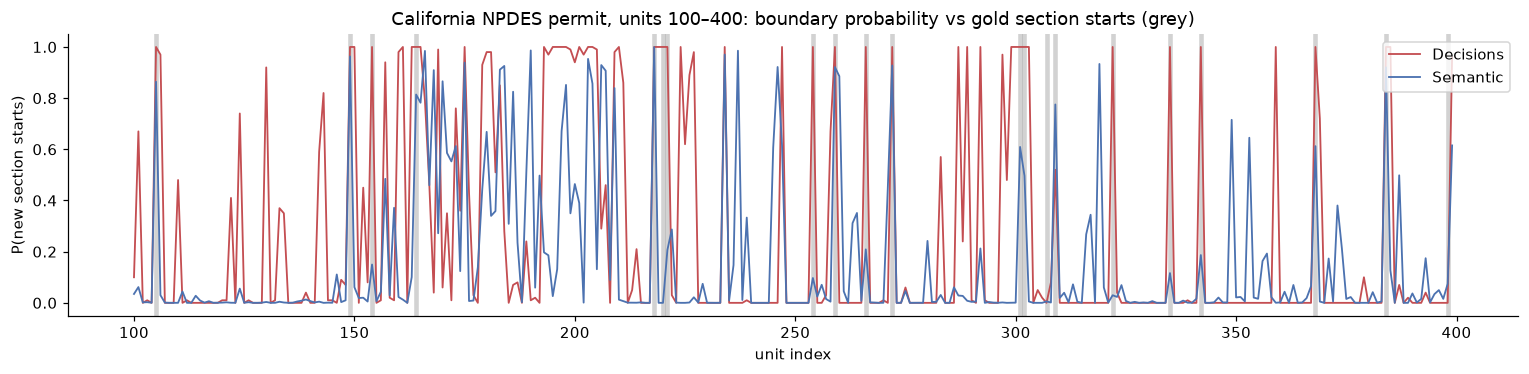

In [10]:
d = corpus["ca-permit-004"]
lo, hi = 100, 400
ustarts = np.array([a for a, _ in d["units"]])
gold_units = [i for i in range(lo, hi) if ((d["gold"] >= ustarts[i]) & (d["gold"] < ustarts[i] + 120)).any()]
fig, ax = plt.subplots(figsize=(14, 3.5))
for g in gold_units:
    ax.axvline(g, color="grey", alpha=0.35, lw=3)
for name, color in [("Decisions + DP", "#C44E52"), ("Semantic + DP", "#4C72B0")]:
    ax.plot(range(lo, hi), d["scores"][name][lo:hi], color=color, lw=1.2, label=name.split(" +")[0])
ax.set_xlabel("unit index"); ax.set_ylabel("P(new section starts)"); ax.legend(loc="upper right")
ax.set_title("California NPDES permit, units 100–400: boundary probability vs gold section starts (grey)")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "boundary_scores_example.png", dpi=150, bbox_inches="tight"); plt.show()

The stretch holds 21 bookmarked starts. The Decisions API gave 0.5 or more at 19 of them and the topic-change reader at 10 (recounted). The red line also rises away from the bands: the Decisions API gave 0.5 or more to 76 paragraphs here, 57 of them not bookmarked. The longest red run, around paragraphs 165 to 212, is Attachment A, a glossary in which each term ("Mixing Zone", "Ocean Waters", "Outflow") starts on its own line. The model called most of these entries a new topic, which is a fair reading of the question it was asked, while the bookmarks list only the attachment. So the figure shows a reader that catches nearly every bookmarked start in this stretch and also marks many smaller units the bookmarks leave out. It does not show the blue line being generally noisier: blue misses half the starts and also rises in places with no band.

Across the whole California permit the Decisions API gave 0.5 or more to 196 of 975 paragraphs, 66 of them among the 78 real starts; the heading rule gave 0.9 to 299 paragraphs, 60 of them real starts (recounted). The two catch a similar number of starts, but the heading rule flags far more paragraphs that are not starts. Section 5.1 turns this into scores.

## 4. Build all chunkings

The next cell applies the five chunkers to every document: the two content-blind cutters directly, and the shared cut-placing step once per reader. The table gives, per method over all 12 documents, the number of chunks, the mean and median size in tokens, the 10th and 90th percentiles and the share of chunks under 50 tokens. Look at how much smaller the chunks of the three readers are than the 400-token budget, and at the share of very small chunks.

In [11]:
METHODS = ["Fixed tokens", "Recursive", "Headings + DP", "Semantic + DP", "Decisions + DP"]
for d in corpus.values():
    d["chunks"] = {"Fixed tokens": fixed_chunks(d), "Recursive": recursive_chunks(d)}
    for name, p in d["scores"].items():
        d["chunks"][name] = segment(d["units"], p, d["text"])

sizes = pd.DataFrame([{"method": m, "doc": fid, "tokens": ntok(d["text"][a:b])}
                      for fid, d in corpus.items() for m in METHODS for a, b in d["chunks"][m]])
size_stats = sizes.groupby("method").tokens.agg(chunks="count", mean="mean", median="median",
                                                p10=lambda s: s.quantile(0.1), p90=lambda s: s.quantile(0.9),
                                                pct_under_50=lambda s: (s < 50).mean()).reindex(METHODS)
size_stats.style.format({"mean": "{:.0f}", "median": "{:.0f}", "p10": "{:.0f}", "p90": "{:.0f}", "pct_under_50": "{:.1%}"})

,chunks,mean,median,p10,p90,pct_under_50
method,,,,,,
Fixed tokens,1987,399,400,400,400,0.0%
Recursive,2020,344,372,247,397,0.5%
Headings + DP,2659,261,269,129,385,0.9%
Semantic + DP,2368,293,313,171,388,0.3%
Decisions + DP,2571,270,298,112,386,3.2%


Fixed tokens makes 1,987 chunks, all of 400 tokens except the last in each document. Recursive packs its pieces close to the limit (median 372). The three readers cut more often and make smaller chunks: Headings + DP 2,659 chunks (median 269), Semantic + DP 2,368 (median 313) and Decisions + DP 2,571 (median 298). Decisions + DP has the most very small chunks, 3.2% under 50 tokens, about 80 chunks. They come from runs of paragraphs the model scored near 1, where the cut-placing step prefers several tiny chunks to leaving a likely cut out; section 6 shows a 44-token chunk holding only a page header and a section heading.

The next chart shows the same distributions as box plots: the box spans the middle half of chunk sizes, the orange line is the median, the whiskers reach the smallest and largest sizes within 1.5 box-lengths, and outliers are hidden.

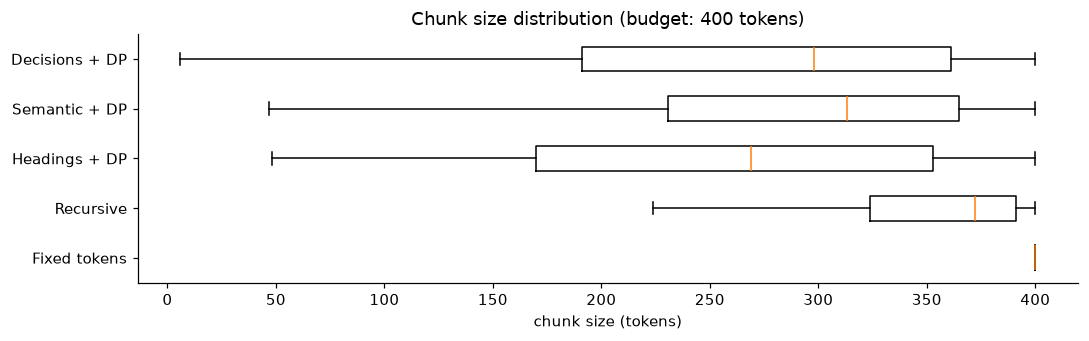

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.boxplot([sizes[sizes.method == m].tokens for m in METHODS], orientation="horizontal", showfliers=False)
ax.set_yticklabels(METHODS); ax.set_xlabel("chunk size (tokens)"); ax.set_title("Chunk size distribution (budget: 400 tokens)")
plt.tight_layout(); plt.show()

Fixed tokens is a single line at 400. Recursive's box sits between about 320 and 390 tokens. The three readers spread much wider, and Decisions + DP's lower whisker reaches nearly zero, the very small chunks described above. Smaller chunks are not a problem in themselves, since each still holds whole paragraphs, but a chunk of a page header and a heading gives a search nothing to match.

## 5. Results

### 5.1 Finding section starts

This test asks whether each reader's probabilities rank the real section starts above the other paragraphs, before any chunks are made. It uses the four documents with at least 10 bookmarked starts. A candidate paragraph counts as a section start if a bookmarked start falls within its first 120 characters.

Average precision (AP) asks how high the real starts sit in the ranking. Walk down the list from the highest probability; each time a real start appears, note the share of real starts among the paragraphs seen so far; AP is the average of those shares. Suppose 10 paragraphs hold 2 real starts, ranked 1st and 3rd: the shares are 1 of 1 and 2 of 3, so AP is (1 + 0.67) / 2 = 0.83. A ranking in random order scores about the share of real starts, so that share is the level a reader with no skill reaches. Higher is better, and 1 is perfect. The heading rule gives only two values, 0.9 and 0.1, so its ranking is one split into two groups.

ROC-AUC is the chance that a randomly chosen real start gets a higher probability than a randomly chosen other paragraph: 0.5 is chance, 1 is perfect.

The first table gives AP per document and reader, the second the mean AP and ROC-AUC over the four documents.

In [13]:
GOLD_DOCS = [fid for fid, d in corpus.items() if len(d["gold"]) >= 10]
rows = []
for fid in GOLD_DOCS:
    d = corpus[fid]
    ustarts = np.array([a for a, _ in d["units"]])
    y = np.array([((d["gold"] >= s) & (d["gold"] < s + 120)).any() for s in ustarts])[1:]
    for name, p in d["scores"].items():
        rows.append({"doc": fid, "scorer": name.split(" +")[0], "AP": average_precision_score(y, p[1:]),
                     "ROC-AUC": roc_auc_score(y, p[1:]), "positives": y.sum(), "candidates": len(y)})
bd = pd.DataFrame(rows)
bd.pivot(index="doc", columns="scorer", values="AP").style.format("{:.2f}").background_gradient(cmap="Greens", axis=1).set_caption("Average precision of section-start detection (higher is better)")

scorer,Decisions,Headings,Semantic
doc,,,
ca-permit-004,0.42,0.17,0.24
coned-25-e-0072-a046df9a-0000-c013-9e7b-73d9aeda68be,0.20,0.09,0.11
ma-ma0100480-980fe11e,0.16,0.19,0.09
me-permit-me0100773,0.61,0.38,0.36


In [14]:
bd.groupby("scorer")[["AP", "ROC-AUC"]].mean().style.format("{:.3f}").set_caption(f"Mean over the {len(GOLD_DOCS)} outlined documents")

,AP,ROC-AUC
scorer,,
Decisions,0.345,0.828
Headings,0.209,0.763
Semantic,0.202,0.698


The share of real starts per document, which `bd` holds in columns `positives` and `candidates` but the tables do not show, is 0.08 for California (78 of 975 paragraphs), 0.20 for Maine (65 of 329), 0.06 for Massachusetts (109 of 1,770) and 0.05 for Con Edison (124 of 2,741), about 0.10 on average. That is the chance level. The Decisions API had the highest AP on three of the four documents and the highest mean, more than three times the chance level, while the other two readers reached about twice the chance level. On Massachusetts the heading rule was ahead. With four documents, the mean rests on four numbers, and one document whose bookmarks differ could move it.

The California result has a simple cause. Its lettered headings, such as "B. California Environmental Quality Act (CEQA)", are bookmarked starts that the heading rule gives 0.1 (section 6), and the rule also gives 0.9 to many short title-case lines that are not headings.

On Massachusetts the bookmarks favour the heading rule. 47 of its 109 bookmarked paragraphs open "Response 1", "Response 2" and so on, the agency's replies to public comments, each bookmarked after the comment it answers. The heading rule gave all 47 the value 0.9; the Decisions API gave 41 of them less than 0.2, treating each reply as part of the comment before it (recounted). Meanwhile the bookmarks leave out the permit's own lettered sections ("B. UNAUTHORIZED DISCHARGES", "C. OPERATION AND MAINTENANCE OF THE SEWER SYSTEM"), which the model marked at 1.00. Both differences count against the model, and neither shows it misreading the document: AP here measures agreement with one publisher's bookmarks.

### 5.2 Chunks that follow sections

Two measures check whether the chunks themselves respect the bookmarked sections, averaged over the four bookmarked documents:

- Section-start recall is the share of bookmarked starts that have a chunk boundary within 200 characters. Higher is better.
- Mixed-section chunks is the share of chunks with a bookmarked start more than 200 characters inside them: chunks that glue two sections together. Lower is better.

In [15]:
def boundary_metrics(chunks, gold, tol=200):
    starts = np.array([a for a, _ in chunks])
    recall = np.mean([np.abs(starts - g).min() <= tol for g in gold])
    mixed = np.mean([((gold > a + tol) & (gold < b - tol)).any() for a, b in chunks])
    return recall, mixed


rows = []
for fid in GOLD_DOCS:
    for m in METHODS:
        r, mx = boundary_metrics(corpus[fid]["chunks"][m], corpus[fid]["gold"])
        rows.append({"doc": fid, "method": m, "section-start recall": r, "mixed-section chunks": mx})
sec = pd.DataFrame(rows).groupby("method")[["section-start recall", "mixed-section chunks"]].mean().reindex(METHODS)
sec.style.format("{:.1%}").background_gradient(subset=["section-start recall"], cmap="Greens").background_gradient(subset=["mixed-section chunks"], cmap="Reds")

,section-start recall,mixed-section chunks
method,,
Fixed tokens,26.3%,28.3%
Recursive,36.2%,21.4%
Headings + DP,67.8%,10.3%
Semantic + DP,54.2%,14.1%
Decisions + DP,77.1%,6.2%


Decisions + DP put a boundary within 200 characters of 77.1% of bookmarked starts, and 6.2% of its chunks hold two sections. Against Fixed tokens (26.3% and 28.3%) that is roughly three times the recall and under a quarter of the mixed chunks; against Headings + DP (67.8% and 10.3%), 9 points more recall and 4 points fewer mixed chunks. Semantic + DP (54.2%, 14.1%) and Recursive (36.2%, 21.4%) fall between. For a reader, a chunk that starts at a section and holds one section is easier to cite: it carries its own heading and section number.

The averages hide one exception. On Massachusetts Headings + DP reached 81% of bookmarked starts against 64% for Decisions + DP (recounted), the bookmark effect described in section 5.1.

### 5.3 Finding the evidence and keeping it whole

This is the test a search user cares about. For each method, every chunk of all twelve documents is embedded into one pooled index. Each question is embedded and the chunks are ranked by similarity to it.

- A pair is a hit at rank k if a chunk among the top k is from the right document and covers at least half of the quote, or 300 of its characters when the quote is long.
- Recall@k is the share of the 276 pairs that are hits within the top k, for k = 1, 3 and 5. MRR, the mean reciprocal rank, averages 1 divided by the rank of the first chunk holding the quote, so a hit at rank 2 adds 0.5. Higher is better for all of them.
- Evidence intact is the share of the 129 pairs whose quote is 600 characters or shorter that lie entirely inside one chunk. A split quote means the search can return at most part of it.

In [16]:
def retrieval_eval(method, ks=(1, 3, 5)):
    index = [(fid, a, b) for fid, d in corpus.items() for a, b in d["chunks"][method]]
    C = embed([corpus[fid]["text"][a:b] for fid, a, b in index])
    Q = embed(evidence.question.tolist())
    order = np.argsort(-(Q @ C.T), axis=1)
    hits, intact = [], []
    for qi, e in enumerate(evidence.itertuples()):
        s, t = e.span
        cover = np.array([fid == e.doc and max(0, min(b, t) - max(a, s)) >= min(0.5 * (t - s), 300) for fid, a, b in index])
        rank = np.flatnonzero(cover[order[qi]])
        hits.append(rank[0] + 1 if len(rank) else np.inf)
        if t - s <= 600:
            intact.append(any(fid == e.doc and a <= s and t <= b for fid, a, b in index))
    hits = np.array(hits)
    return {"method": method, **{f"recall@{k}": (hits <= k).mean() for k in ks}, "MRR": np.mean(1 / hits),
            "evidence intact": np.mean(intact), "_hits": hits}


ret = pd.DataFrame([retrieval_eval(m) for m in METHODS]).set_index("method")
ret.drop(columns="_hits").style.format("{:.3f}").background_gradient(cmap="Greens")

,recall@1,recall@3,recall@5,MRR,evidence intact
method,,,,,
Fixed tokens,0.290,0.460,0.525,0.403,0.915
Recursive,0.232,0.453,0.547,0.374,0.930
Headings + DP,0.246,0.428,0.496,0.369,0.922
Semantic + DP,0.243,0.428,0.507,0.366,0.922
Decisions + DP,0.221,0.395,0.500,0.350,0.783


Recall@5 lies between 0.50 and 0.55 for all five methods. The chart below draws 95% bootstrap intervals for recall@5, from resampling the 276 pairs 2,000 times; as drawn, each spans roughly 0.06 either side of its bar, and all five overlap. Those intervals treat the pairs as independent, which they are not, since quotes repeat; the true uncertainty is wider. Fixed tokens has the best recall@1 and MRR, Decisions + DP the lowest, but the differences are of the same size as the intervals. The way of cutting made no measurable difference to finding the evidence: 86 pairs were in the top five under every method and 84 under none (recounted).

Evidence intact is the one clear difference: 0.783 for Decisions + DP against 0.915 to 0.930 for the others, that is 101 of the 129 short quotes kept whole against 118 to 120 (recounted).

How to read the next chart. The left panel shows recall@5 for each method as a bar, with a black line for its 95% bootstrap interval. The right panel repeats the section-structure measures of section 5.2 for comparison: green is section-start recall, red the share of mixed-section chunks. Compare the lengths of the bars across the two panels: the right panel separates the methods, the left does not.

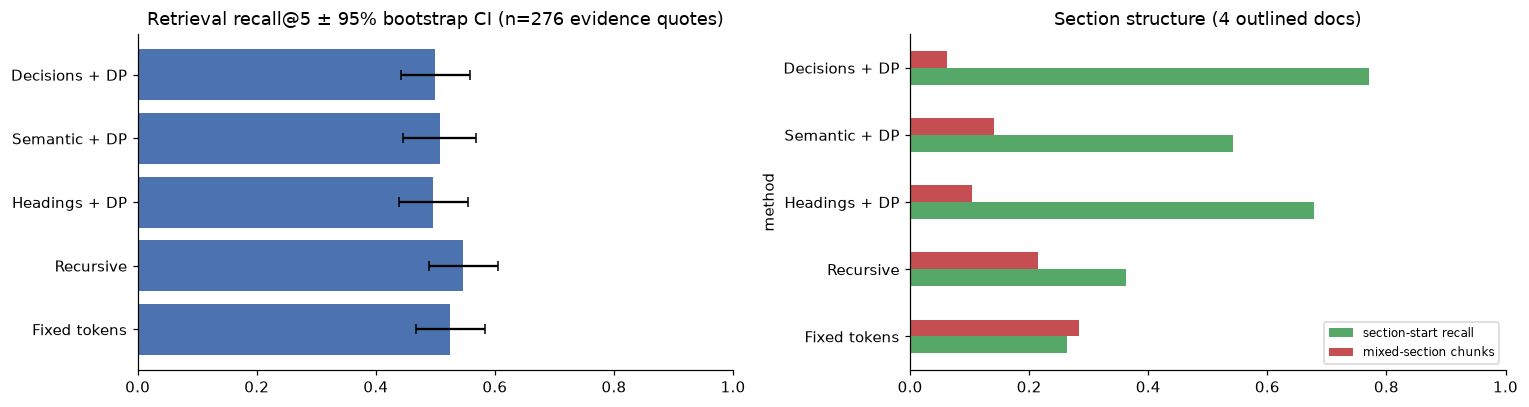

In [17]:
rng = np.random.default_rng(0)
boot = {m: [(ret.loc[m, "_hits"][rng.integers(0, len(evidence), len(evidence))] <= 5).mean() for _ in range(2000)] for m in METHODS}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
lo_hi = np.array([np.percentile(boot[m], [2.5, 97.5]) for m in METHODS])
axes[0].barh(METHODS, ret["recall@5"], xerr=[ret["recall@5"] - lo_hi[:, 0], lo_hi[:, 1] - ret["recall@5"]], color="#4C72B0", capsize=3)
axes[0].set_xlim(0, 1); axes[0].set_title(f"Retrieval recall@5 ± 95% bootstrap CI (n={len(evidence)} evidence quotes)")
sec.plot.barh(ax=axes[1], color=["#55A868", "#C44E52"]); axes[1].set_xlim(0, 1); axes[1].set_title(f"Section structure ({len(GOLD_DOCS)} outlined docs)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Repeated quotes move these averages in blocks. The Georgia permit's cover page is the evidence for all 20 Georgia questions. Fixed tokens, Recursive, Headings + DP and Semantic + DP put it in the top five for 17 to 19 of them, Decisions + DP for 6 (recounted). That one quote accounts for 11 to 13 pairs of Decisions + DP's gap on Georgia. Leaving out the two most repeated quotes (the cleanup permit's cover, 25 pairs, and Georgia's, 20), Decisions + DP found 126 of the remaining 231 pairs in the top five, between Recursive's 128 and Fixed tokens' 123 (recounted).

The split quotes behave the same way. Decisions + DP split 28 of the 129 short quotes, the other methods 9 to 11. But the 129 pairs hold only 47 distinct quotes, and the 28 splits are 6 distinct quotes:

| Split quote | Pairs | Split by |
|---|---:|---|
| Con Edison cover page: case caption, then "JOINT PROPOSAL / November 5, 2025" | 18 | Decisions + DP only |
| Recall notice: reimbursement table, last row's part numbers | 4 | Decisions + DP, Headings + DP, Fixed tokens |
| Georgia 7.12: revocation heading, its text, then 7.13 | 2 | Decisions + DP, Fixed tokens |
| Recall notice: reference images for rust and water damage | 2 | Decisions + DP, Headings + DP |
| Georgia 3.2.3, ending with the next heading "3.3 Equipment" | 1 | Decisions + DP, Headings + DP |
| Liberty cover page: case caption, then the testimony title and dates | 1 | Decisions + DP only |

Counted once each, Decisions + DP kept 41 of the 47 distinct short quotes whole, Fixed tokens and Headings + DP 42, Semantic + DP 44 and Recursive 45 (recounted). The other methods' splits repeat too: 8 of Recursive's 9 split pairs are one recall-notice quote. Decisions + DP still splits the most distinct quotes, by 1 to 4, and two of its six splits are cover pages, cut between a case caption and the document title beneath it, a boundary the model marked at probability 1.0.

### 5.4 One pair from start to finish

The next cell takes the middle Georgia pair in the evidence table and prints, for each method, the chunk holding the start of its quote: its size, the token at which the quote starts, and the chunk's first and last characters (¶ marks a paragraph break). The pair is question `facility-065-weekly-maintenance-not-daily-ve` with its quote of condition 5.2.1, the baghouse check from the opening example. A structure-following chunk should open at the heading "5.2 Specific Monitoring Requirements".

In [18]:
e = evidence[evidence.doc == "epa-argos-atlanta-title-v-permit-2025"].iloc[len(evidence[evidence.doc == "epa-argos-atlanta-title-v-permit-2025"]) // 2]
d = corpus[e.doc]
print("Q:", e.question, "\nEvidence:", e.quote[:150].replace("\n", " "), "…\n")
for m in METHODS:
    a, b = next((a, b) for a, b in d["chunks"][m] if a <= e.span[0] < b)
    chunk = d["text"][a:b].replace("\n\n", " ¶ ")
    print(f"── {m}: {ntok(d['text'][a:b])} tokens, evidence starts at token {ntok(d['text'][a:e.span[0]])}")
    print(f"   starts: {chunk[:150]!r}\n   ends:   {chunk[-110:]!r}\n")

Q: Resolve the exact Atlanta FRS address/permit identity before reviewing this 2025 air source: register the separate maintenance cadence and required indicators/actions. 
Evidence: 5.2.1 The Permittee shall perform a check of visible emissions from all baghouses (including process baghouses) controlling emissions from sources lis …

── Fixed tokens: 400 tokens, evidence starts at token 348
   starts: '391-3-1-.02(9)(a)] ¶ 4.2 Specific Testing Requirements ¶ 4.2.1 In accordance with the applicable provisions of 40 CFR 60.8, for any equipment which is'
   ends:   'es listed in Section 3.1 of this permit, and from sources added or replaced in accordance with this permit and'

── Recursive: 323 tokens, evidence starts at token 0
   starts: '5.2.1 The Permittee shall perform a check of visible emissions from all baghouses (including process baghouses) controlling emissions from sources lis'
   ends:   'For sources that exhibit visible emissions, the Permittee shall comply with paragraph b.

The question, as printed, is a templated instruction whose opening clause is about the facility's identity. Its recorded answer is that baghouses get at least weekly maintenance checks and that the daily visible-emissions check has a different purpose. It cites four quotes, three of them in this permit; this one begins "5.2.1 The Permittee shall perform a check of visible emissions from all baghouses" and runs 2,526 characters through the daily check and its steps a to c, so it is a long quote and is not part of the evidence-intact measure.

Each step for this pair:

1. Preparation. The permit becomes 292 candidate paragraphs; paragraph 69 opens "5.1 General Monitoring Requirements" and paragraph 70 opens "5.2 Specific Monitoring Requirements".
2. The model call. Section 3.4 showed the request and reply: p = 1 for paragraph 69 and p = 0 for paragraph 70, at a cost of \$0.0010.
3. The chunks. Headings + DP cut exactly at "5.2" (the quote starts at token 7), and Recursive at "5.2.1" (token 0). Decisions + DP followed the model's 0 and put 5.1 and the start of 5.2 in one 380-token chunk, the same chunk Semantic + DP produced (token 124). Fixed tokens started its chunk in section 4.2 and cut 52 tokens into the condition (token 348 of 400), as in the first complication of the opening example.
4. The search. The quote is long, so a chunk counts as holding it if it covers 300 of its characters. The first chunk holding it ranked 14th (Fixed tokens), 19th (Recursive), 18th (Headings + DP), 8th (Semantic + DP) and 10th (Decisions + DP) (recounted from `retrieval_eval`'s `_hits`). No method put it in the top five, so this pair is a miss for all five. The question's long opening clause is about identity, not baghouses, which may be why no chunk of condition 5.2.1 ranked near the top.

The pair shows both halves of the result in one place: the model's probabilities decide whether a chunk opens at the right heading, and for this question the search missed the passage whichever way it was cut.

### 5.5 Spend

The next cell adds up the cost recorded in every cached Decisions reply: \$0.27 over 278 calls. The embedding endpoint is free.

In [19]:
spent = sum(v["usage"]["cost"] for v in decision_cache.data.values() if "usage" in v)
print(f"Total Decisions API spend recorded in cache: ${spent:.2f} over {len(decision_cache.data)} calls")

Total Decisions API spend recorded in cache: $0.27 over 278 calls


## 6. Error analysis

Each case below is a measured result with its document and question IDs. Together they show where the Decisions API's lead on section starts comes from, why its splits concentrate in a few places, and why the search did not reward cleaner chunks.

### A cover page counted eighteen times

Eighteen Con Edison questions in `nydps-coned-25-e-0072/adopted-procedure-questions.jsonl` (for example `coned-adopted-storm-trigger-boundary`) cite the filing's cover page as one of their quotes: the two case captions, "for Electric Service" and "for Gas Service", then "JOINT PROPOSAL" and "November 5, 2025". The extractor gives this as two paragraphs, and the Decisions API scored the second, "JOINT PROPOSAL / November 5, 2025", as a new section with probability 1.0. Decisions + DP cut there, so the 423-character quote is split in all 18 pairs. The other four methods kept the cover in one chunk.

The cut is defensible: the caption names the case and the title names the document. The quote is there to show which document an answer comes from, and the answers themselves are deep inside a 387-page filing. One placement decision on one page becomes 18 of the 28 splits. Without it, Decisions + DP would have kept 119 of the 129 short quotes whole, the same as Headings + DP and Semantic + DP. This is the clearest case in this notebook where the measure misleads.

### A table row cut from its part numbers

The recall notice (`nhtsa-25v037-rcmn-25v037-0197`) has a reimbursement table with three rows, each a campaign code, a labour time and a list of parts. Four questions, such as `nhtsa-technical-rust-labor`, quote the whole table. The last row's part numbers, "LT226A02EX LT226B02EX", are a short text block. Because short blocks merge forward, they joined the next paragraph, which continues "REPAIR PROCEDURE: 1. Park the vehicle on a flat, level surface". The Decisions API scored that paragraph 0.99, reasonably, since it opens a new part of the notice. Decisions + DP cut before it: one chunk ends with the last row's "Replace relays. Clean terminals.", and the next 84-token chunk opens with that row's part numbers and the repair procedure.

For `nhtsa-technical-rust-labor`, which asks for the campaign code, labour time and parts of exactly that row, the answer is now in two chunks. The heading rule scored the same paragraph 0.9 and cut in the same place. The fault is in how paragraphs are built, not in either reader: a cut can only fall between paragraphs, and this paragraph starts one block before the section it introduces.

### A heading cut from its own text

On page 23 of the Georgia permit, section 7.12 reads "Revocation of Existing Permits and Amendments", followed by a sentence and a one-row table naming the revoked permit. Two questions quote it (`facility-065-old-permit-revocation-event`, `facility-065-predecessor-to-current-record-change`). The page header and the heading form paragraph 146; the sentence and table form paragraph 147. The Decisions API gave 1.00 to 146, to 147 and to 148 ("7.13 Pollution Prevention Not Applicable"). For paragraph 147 that is wrong: "The following Air Quality Permits ... are hereby revoked" continues the heading above it. Decisions + DP produced three chunks of 44, 65 and 40 tokens; the first holds only the page header and the heading. This is a model error, and it is the kind of run that produces Decisions + DP's 3.2% of chunks under 50 tokens. Recursive, Headings + DP and Semantic + DP kept the quote whole; Fixed tokens split it.

### A quote that ends with the next heading

Question `facility-065-fuel-authority-and-monthly-records` quotes Georgia condition 3.2.3, "The Permittee is authorized to burn natural gas and landfill gas as fuel in the Finish Mill (EU208)", and the quote ends with the next heading, "3.3 Equipment". Decisions + DP and Headings + DP both cut at that heading, a correct section start, so the quote counts as split, although everything the question needs is in the first chunk. The intact measure cannot tell this split from a harmful one.

### A typical success

In the California permit, lettered headings such as "B. California Environmental Quality Act (CEQA)" (paragraph 596) and "D. Impaired Water Bodies on CWA 303(d) List" (paragraph 636) are bookmarked starts. The heading rule gave them 0.1, because its pattern accepts numbers such as "5.2" but not a single letter and a full stop, and these headings fail its strict title-case test (an acronym in capitals or a lower-case "on" is enough). The Decisions API gave both 1.0; across the permit it gave more than 0.9 to 10 bookmarked starts that the heading rule missed (recounted). This is where its AP lead on California (0.42 against 0.17) comes from: it does not depend on how a heading is typed.

### A question no method answered fully

Question `nh-root-reasoning-007` asks which sample type the New Hampshire permit requires for total suspended solids (TSS) at outfall 001, and whether a sample collected over exactly 15 minutes would meet its definition. The recorded answer is no: the table row "Total Suspended Solids (TSS) 30 mg/L 50 mg/L 1/Week Grab" requires a grab sample, and footnote 5 defines a grab sample as "an individual sample collected in a period of less than 15 minutes". Only Decisions + DP put the table row in the top five (rank 3; the others ranked it 6, 10, 177 and 148). No method put the footnote in the top five (ranks 7 to 13). The answer needs a table cell and a footnote, and each method found at most one of them. In most of the 84 pairs no method found, the search reached the right filing and missed the passage: the top-ranked chunk came from the right document in 59 to 67 of them, depending on the method (recounted).

### What these examples cannot show

They show what each reader scored and where each cutter cut, not why the model scored a paragraph as it did. The six split quotes and the handful of disagreements are too few to estimate how often each kind of error happens in other filings.

## 7. What the evidence supports

- For reading and citing, the Decisions API's cuts follow the structure of long permits and filings better than the free alternatives tested: more chunks start at a section (77% against 68% for Headings + DP) and fewer mix two (6% against 10%), for \$0.39 per million tokens of document. The advantage is clearest on documents whose headings are not uniformly numbered, such as the California permit.
- For finding answers, the way of cutting did not matter here. All five methods found 50% to 55% of the quotes in their top five chunks. A team whose goal is search alone has no reason in this evidence to pay for model-placed cuts; better questions, separate searches per document or a better embedding model are more likely places to look.
- Return the neighbouring chunk with each hit, or let chunks overlap by a sentence or two. The splits found here sit at boundaries the cutters had good reason to choose, such as a table's last cell glued to the next heading or a cover-page caption, and the answer often lies just across them. This fix was not tested here.
- Build candidate paragraphs so that a short block at the end of a section stays with that section. Two of the six distinct splits by Decisions + DP trace to a short block merged into the next section's paragraph.
- Count distinct quotes, not question-quote pairs, before reading a split rate. Here 18 of 28 splits were one cover page.

The uncertainty that most needs another experiment is whether cleaner chunks help search with natural questions over a larger set of documents whose sections are marked by people rather than by publishers' bookmarks.

## 8. Limitations

- Older public data. This notebook predates the repository's rule that test data must be newer than the models. The filings are public, dated between October 2021 and August 2026 in the catalogue, and no training cutoff or release date is recorded for either model, so the notebook cannot rule out that a model saw some of them. Treat the scores as an upper bound.
- Partial bookmarks on four documents. The section tests use publishers' bookmarks, which skip some real sections (the Massachusetts permit's lettered parts, the California glossary) and include entries that are arguably not sections (replies to comments). Only four of twelve PDFs have usable bookmarks, and the mean AP rests on those four.
- An unreviewed, repetitive question bank. No file records who wrote the questions, 50 of the 142 are marked as pending review, many are long templated instructions, and the 276 pairs repeat 116 distinct quotes, three cover pages alone accounting for 63 pairs. Rates over pairs weight those quotes heavily, and the bootstrap intervals understate the uncertainty.
- One search setup. Every cutter was searched with the same free embedding model and one pooled index of all twelve documents, with each question's full text as the query. A different model, per-document filtering or plainer questions could change the search results and the gaps between methods.
- One prompt, one window size, no versions. The Decisions API was asked one wording of the question with windows of 40 paragraphs, its probabilities were not checked for calibration, and neither model has a dated version recorded.
- Counts not printed by the notebook. The distinct-quote split counts and per-pair ranks were recounted by replaying this notebook's code. The analysis was not registered before the results were seen. The run history, including an earlier configuration whose results this notebook does not use, is in [`data/PROTOCOL.md`](data/PROTOCOL.md).

## 9. How to reproduce

From this folder, the notebook replays everything without model calls:

```bash
jupyter nbconvert --to notebook --execute --inplace 04_industry_document_chunking.ipynb
```

The first run downloads the 12 PDFs into `data/docs/` (git-ignored) and stops if a file's sha256 differs from the catalogue. A request missing from the caches needs `OPENROUTER_API_KEY`. Dependencies are in `requirements.txt` at the repository root.

| File in `data/` | What it holds |
|---|---|
| `catalog/<dataset>/files.jsonl` | One row per source PDF: address, sha256, size, licence, catalogue date and notes |
| `catalog/<dataset>/*.jsonl` (other files) | The question banks: question, answer, evidence quotes with page locators, origin and verification status |
| `decisions_cache_chunking.jsonl` | The 278 Decisions API replies, keyed by a hash of the full request: one probability per question, input tokens, cost and time |
| `embeddings_cache.npz` | 16,763 embedding vectors of 512 numbers each, keyed by a hash of model name and text |
| `PROTOCOL.md` | Run history and settings |

Spend: the Decisions API cost \$0.27 for 278 calls; the embedding endpoint is free.

## 10. Future work and further reading

### Future work

- Test the fix this notebook recommends. Add a one- or two-sentence overlap to Decisions + DP, or return the neighbouring chunk with each hit, and measure evidence intact on distinct quotes and recall@5. Motivated by the six distinct quotes it split, against two to five for the other methods.
- Keep end-of-section blocks with their section. Merge a short block backward when it follows a table or figure, and re-score the recall-notice table and the Georgia 7.12 cases. Motivated by the table row whose part numbers were glued to "REPAIR PROCEDURE:".
- Mark section starts by hand in the eight PDFs without usable bookmarks, at an agreed level (part, section, condition), so that AP no longer depends on what each publisher chose to bookmark. Motivated by the Massachusetts comment replies and the California glossary.
- Separate search difficulty from cutting. Rerun the search with plain one-sentence questions, one search per document and each distinct quote counted once, and see how much of the 0.50 to 0.55 recall@5 and the gaps between methods remain. Motivated by the Georgia cover page moving 11 to 13 pairs at once.
- Extract tables as tables. Many quotes are table cells split across text blocks; compare a table-aware extractor on the permits and the Con Edison filing.

### Further reading

Links checked on 17 October 2026.

- [Late Chunking: Contextual Chunk Embeddings Using Long-Context Embedding Models](https://arxiv.org/abs/2409.04701) (Günther et al., 2024). Embeds the whole document before splitting, so a chunk's vector keeps context across a boundary, one answer to the split quotes found here.
- [RAPTOR: Recursive Abstractive Processing for Tree-Organized Retrieval](https://arxiv.org/abs/2401.18059) (Sarthi et al., 2024). Retrieves from a tree of condensed segments, an alternative to choosing one level of boundaries.
- [Docling Technical Report](https://arxiv.org/abs/2408.09869) (Auer et al., 2024). Open-source PDF conversion with layout and table-structure models, a candidate for table-aware extraction.
- [Introducing Contextual Retrieval](https://www.anthropic.com/news/contextual-retrieval) (Anthropic, 2024). Adds chunk-specific context before indexing instead of moving the boundaries, and reports 49% fewer top-20 retrieval failures.
- [Is Semantic Chunking Worth the Computational Cost?](https://arxiv.org/abs/2410.13070) (Qu et al., 2024). Finds that semantic chunking's extra compute is not consistently repaid in retrieval tasks, in line with the flat recall@5 across cutters here.